# WY2021 forcing at the radar snow-model sites

Compare the hourly forcing at each of the five established SNOWPACK model points. The figures use daily means and daily precipitation totals. Set a site subset and shorter dates for hourly inspection. The CSV preserves the hourly values in the selected date range. Curves appear as validated forcing files become available. Surface-only fallback identifies hours where the downscaler could not use a screened pressure-profile bracket.

In [1]:
from pathlib import Path
import sys

cwd = Path.cwd()
folders = (cwd, cwd / "downscaling", cwd / "jif_snow_modeling" / "downscaling")
folder = next((p for p in folders if (p / "radar_icefield_comparison.py").is_file()), None)
if folder is None:
    raise FileNotFoundError("Open the notebook from the repos workspace or JIF repository.")
sys.path.insert(0, str(folder))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
import xarray as xr
from radar_icefield_comparison import NATIVE, RUN, SURFACE, elevation_table, geometry, load_forcing, radar_sites

sites = radar_sites()
grids, cells = geometry(sites)
output = folder / "outputs"

selected_sites = sites.index.tolist()  # For example, ["TKG4", "DG1"]
start, end = "2020-10-01", "2021-09-30"
frequency = "D"  # None for hourly
frames = {}
for name in selected_sites:
    series = load_forcing(name, cells)
    frames[name] = {label: data.loc[start:end] for label,data in series.items()}
available = {(site,label): data for site,group in frames.items() for label,data in group.items()}
if available:
    output.mkdir(exist_ok=True)
    pd.concat(available, axis=1, names=["site","grid","variable"]).to_csv(
        output / "radar_sites_forcing_WY2021.csv",index_label="time_utc")
else:
    print("Waiting for the paired WY2021 surface forcing.")


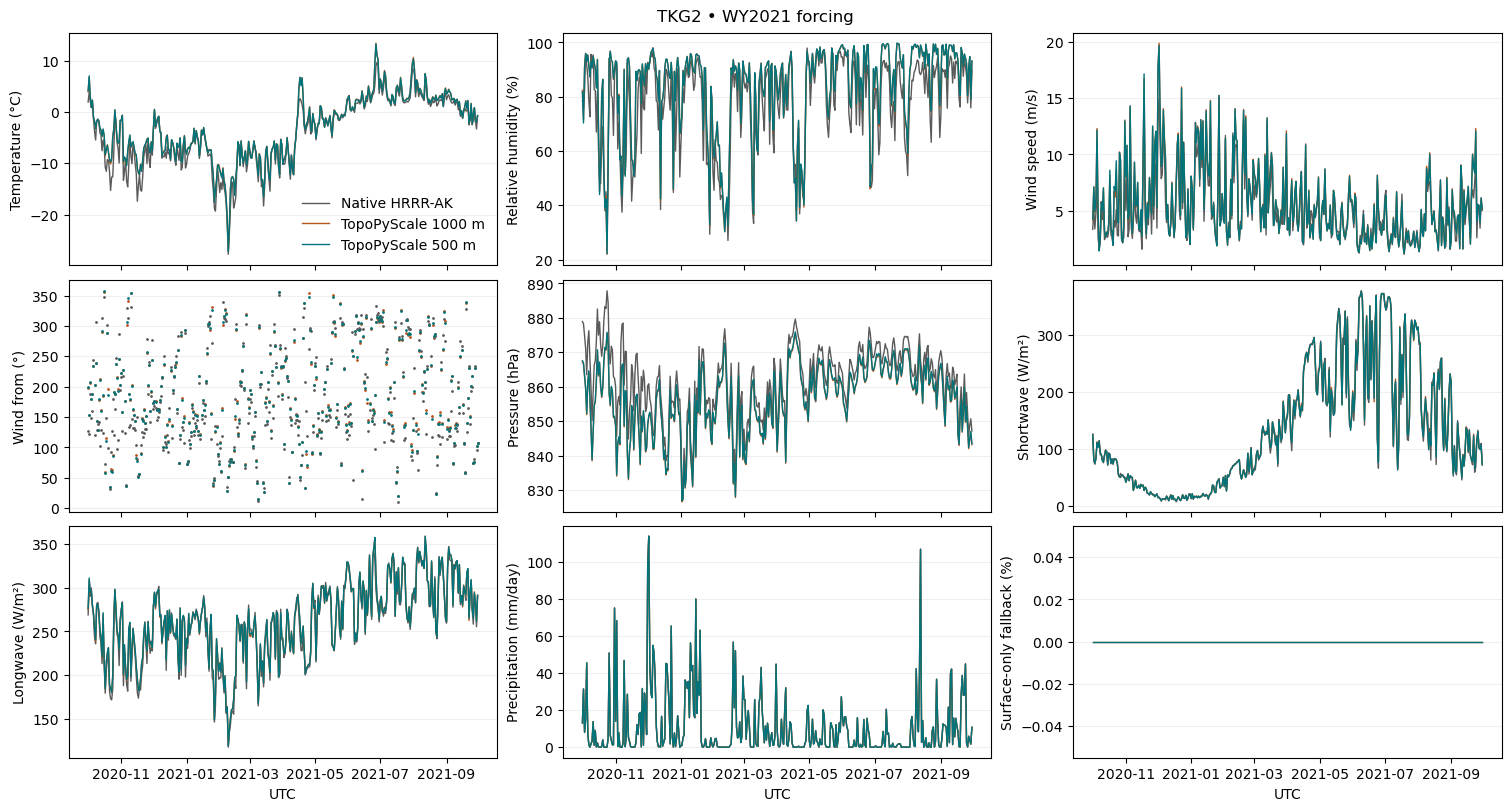

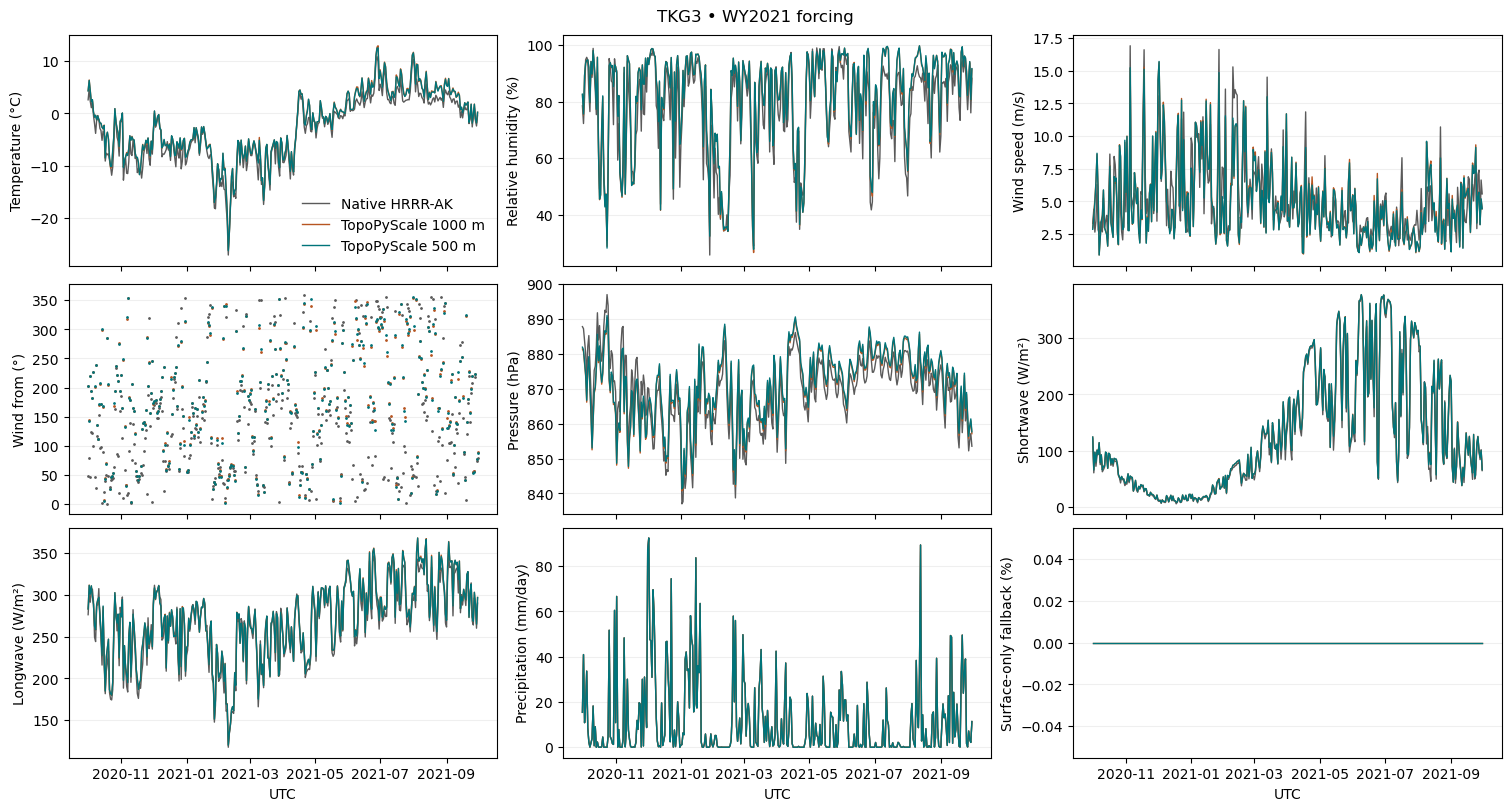

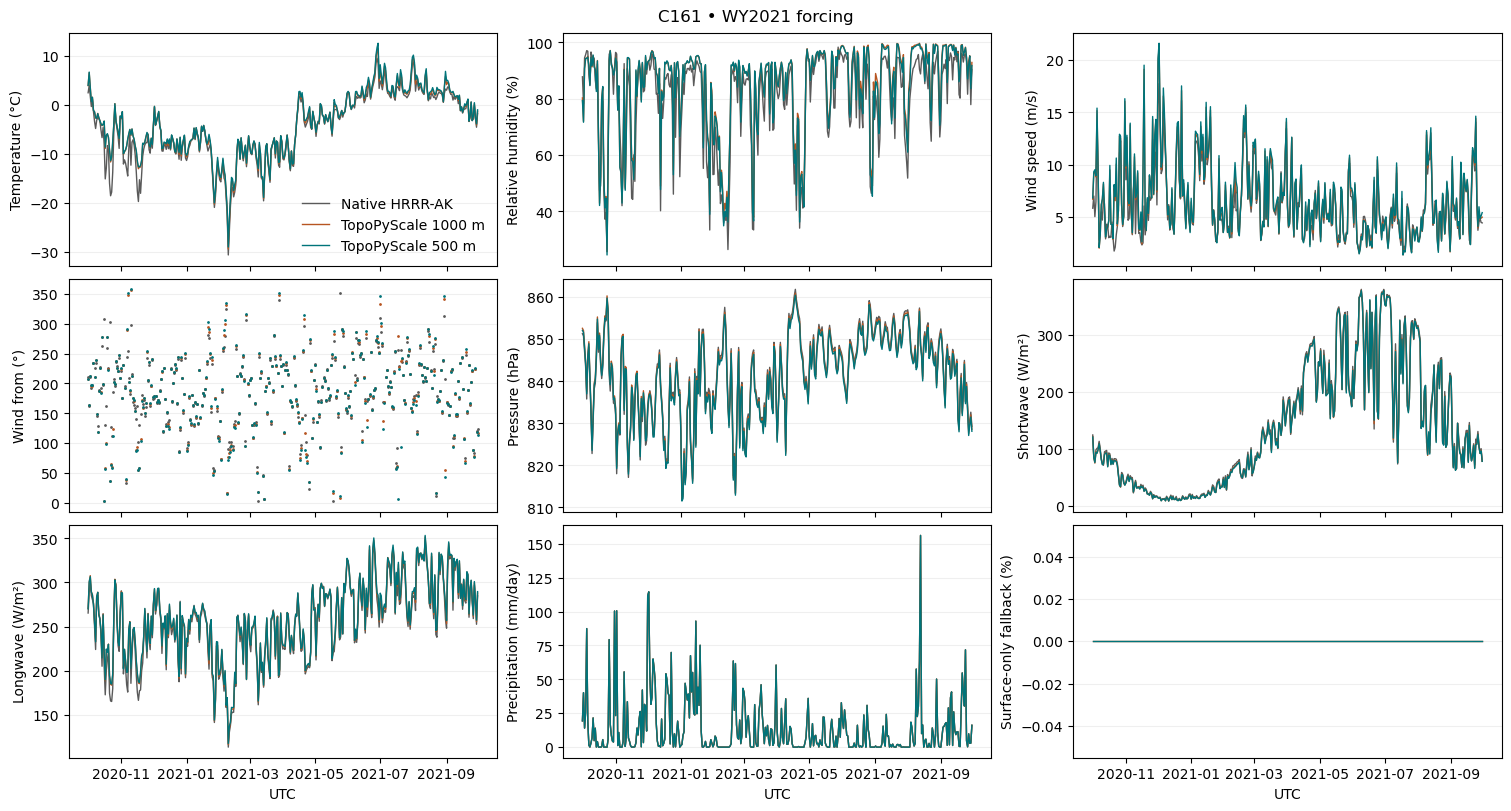

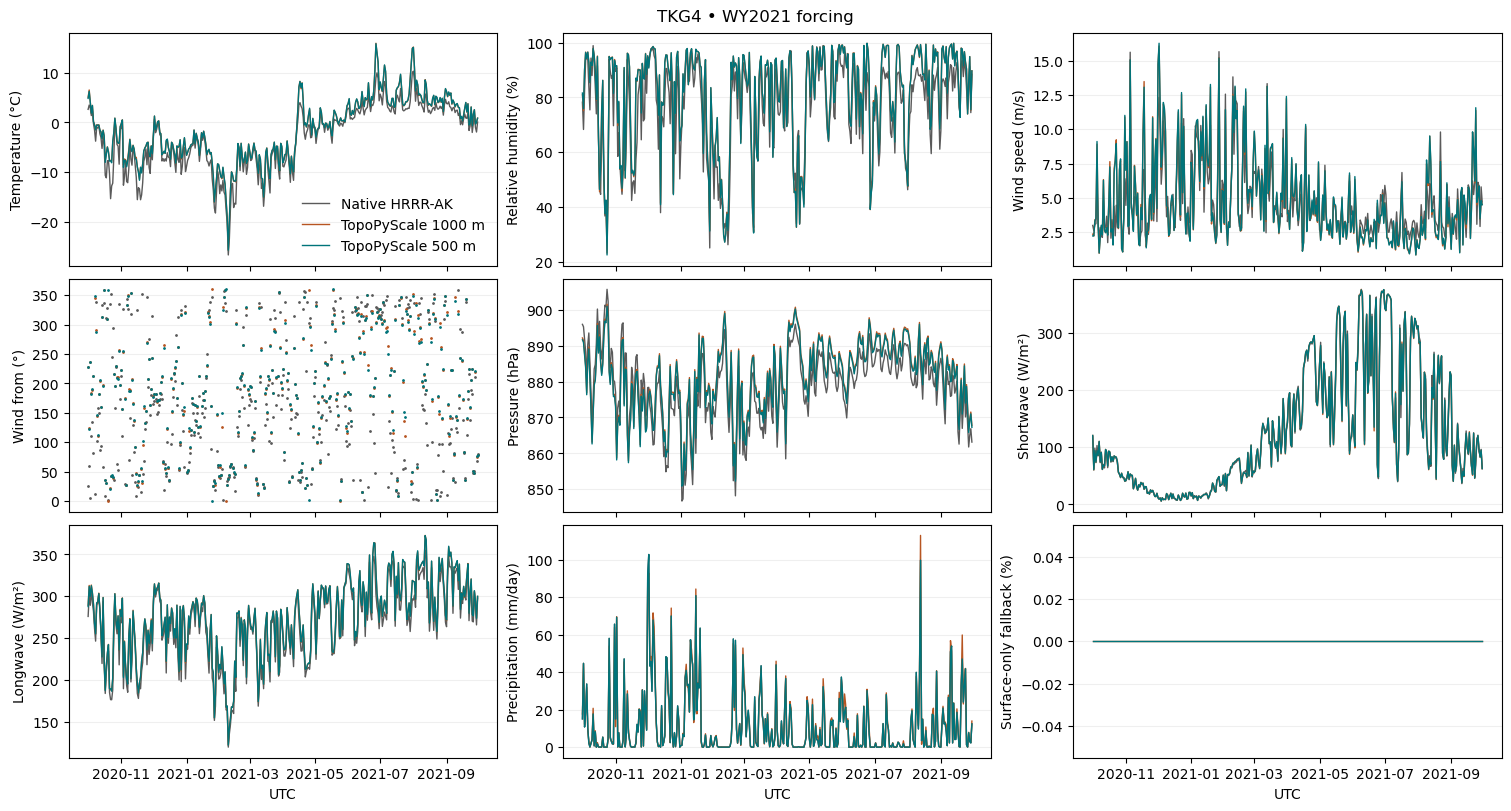

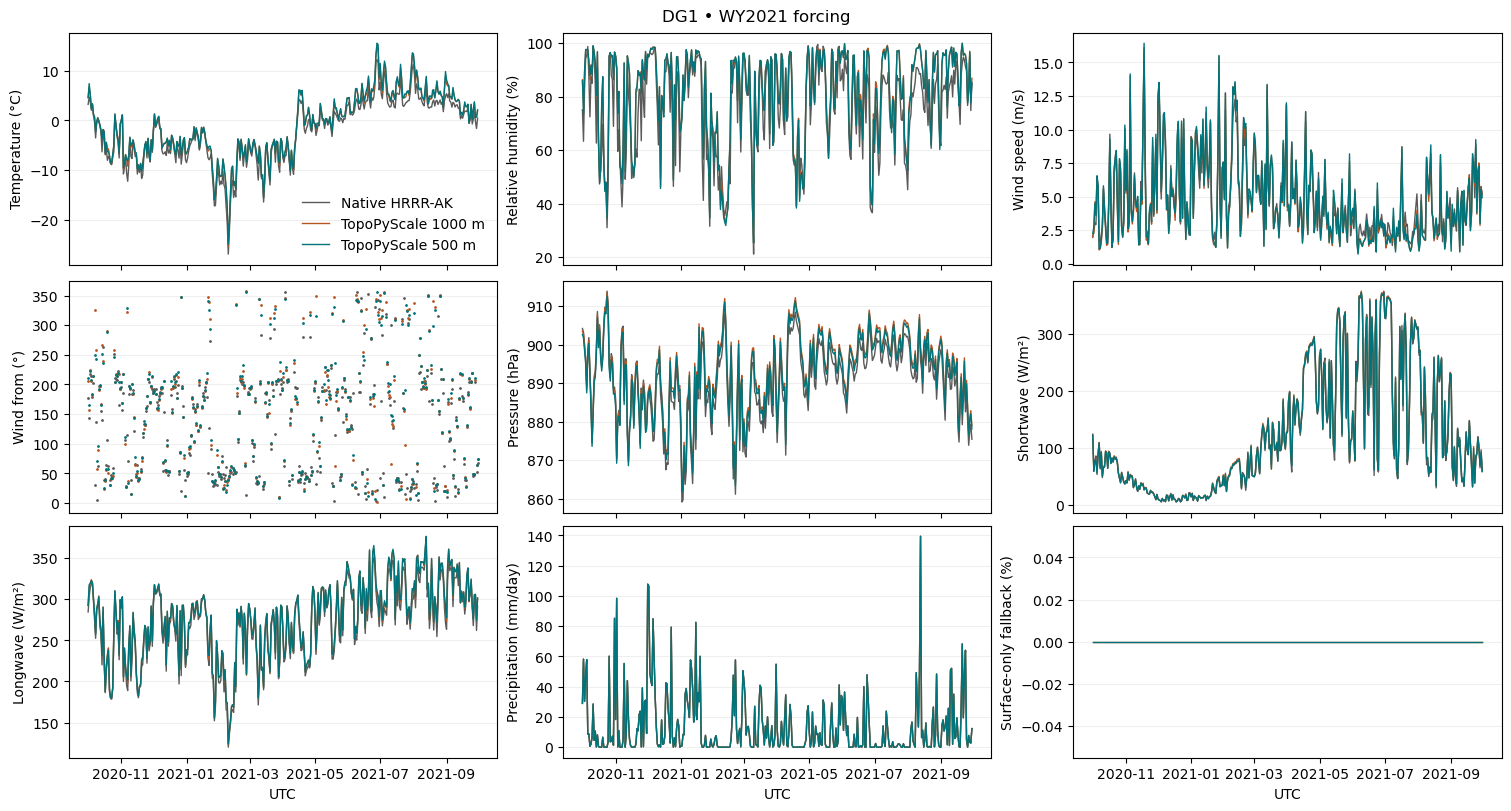

In [2]:
fields = {
    "temperature_C":"Temperature (°C)", "rh_percent":"Relative humidity (%)",
    "wind_m_s":"Wind speed (m/s)", "wind_direction":"Wind from (°)",
    "pressure_hPa":"Pressure (hPa)", "shortwave_W_m2":"Shortwave (W/m²)",
    "longwave_W_m2":"Longwave (W/m²)",
    "precip_mm":"Precipitation (mm/day)" if frequency else "Precipitation (mm/hour)",
    "fallback_percent":"Surface-only fallback (%)",
}
colors = {"Native HRRR-AK":"#5a5a5a","TopoPyScale 1000 m":"#b75521","TopoPyScale 500 m":"#00747a"}

def plot_values(data, field):
    if field == "wind_direction":
        winds = data[["u_east_m_s","v_north_m_s"]]
        if frequency:
            winds = winds.resample(frequency).mean()
        return np.rad2deg(np.arctan2(-winds.u_east_m_s,-winds.v_north_m_s)) % 360
    if field not in data:
        return None
    values = data[field]
    if frequency:
        series = values.resample(frequency)
        return series.sum(min_count=1) if field == "precip_mm" else series.mean()
    return values

for site, members in frames.items():
    if not members:
        continue
    fig, axs = plt.subplots(3,3,sharex=True,figsize=(15,8),layout="constrained")
    fig.suptitle(f"{site} • WY2021 forcing")
    for ax,(field,label) in zip(axs.ravel(),fields.items()):
        for grid,data in members.items():
            values = plot_values(data, field)
            if values is not None:
                direction = field == "wind_direction"
                ax.plot(values.index,values,label=grid,color=colors[grid],
                        linewidth=0 if direction else 1,marker="." if direction else None,
                        markersize=2)
        ax.set_ylabel(label)
        ax.grid(axis="y",alpha=.2)
    axs[0,0].legend(frameon=False)
    for ax in axs[-1]:
        ax.set_xlabel("UTC")
    plt.show()


## Site and grid-cell elevations

The site elevations come from the existing SNOWPACK run inputs. TKG4 uses the established model point and its 1,120 m elevation. The native HRRR-AK value is the WY2021 median at the containing native cell, with the minimum and maximum shown separately. The downscaled values are cell-average ArcticDEM elevations. Δ is grid-cell elevation minus site elevation. Vertical datums have not been independently reconciled. Blank values indicate missing coverage or terrain.

In [3]:
display(elevation_table(cells, output))

,Site elevation (m),Native HRRR-AK elevation (m),Native HRRR-AK Δ (m),Native min–max (m),TopoPyScale 1000 m elevation (m),TopoPyScale 1000 m Δ (m),TopoPyScale 500 m elevation (m),TopoPyScale 500 m Δ (m)
site,,,,,,,,
TKG2,1326.0,1306.5,-19.5,1234.8–1306.5,1343.0,17.0,1339.9,13.9
TKG3,1203.0,1246.1,43.1,1152.9–1246.1,1210.5,7.5,1205.5,2.5
C161,1483.0,1477.3,-5.7,1477.3–1494.6,1481.2,-1.8,1485.9,2.9
TKG4,1120.0,1156.2,36.2,1078.6–1156.2,1112.0,-8.0,1116.7,-3.3
DG1,1018.0,1041.8,23.8,1003.4–1041.8,1007.6,-10.4,1015.6,-2.4
